# 06 — Model Evaluation and Explainability

## Project: PlantLeafNet — Advanced Plant Disease Detection

### Objectives
1. Evaluate final model performance on the independent test dataset.
2. Analyse confusion matrices.
3. Examine per-class precision, recall and F1-score.
4. Identify frequently misclassified plant diseases.
5. Apply Grad-CAM to visualize important image regions.
6. Investigate model decision-making and potential limitations.

### Models
- MobileNetV3-Large Fine-Tuned
- EfficientNetV2-S Fine-Tuned

### Evaluation metrics
- Accuracy
- Precision
- Recall
- Macro F1-score
- Confusion Matrix
- Per-class classification metrics

### Explainability
Gradient-weighted Class Activation Mapping (Grad-CAM) will be used to visualize image regions that influence model predictions.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F

from pathlib import Path
from PIL import Image

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support
)

from torchvision import models, transforms
from tqdm.auto import tqdm

sns.set_theme(style="whitegrid")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
PROJECT_DIR = Path("/content/drive/MyDrive/PlantLeafNet")

MODEL_DIR = PROJECT_DIR / "models"
RESULT_DIR = PROJECT_DIR / "results"

print("Models directory:", MODEL_DIR)
print("Results directory:", RESULT_DIR)

Models directory: /content/drive/MyDrive/PlantLeafNet/models
Results directory: /content/drive/MyDrive/PlantLeafNet/results


In [ ]:
mobilenet_report = pd.read_csv(
    RESULT_DIR / "mobilenet_test_classification_report.csv",
    index_col=0
)

efficientnet_report = pd.read_csv(
    RESULT_DIR / "efficientnet_test_classification_report.csv",
    index_col=0
)

mobilenet_cm = pd.read_csv(
    RESULT_DIR / "mobilenet_test_confusion_matrix.csv",
    index_col=0
)

efficientnet_cm = pd.read_csv(
    RESULT_DIR / "efficientnet_test_confusion_matrix.csv",
    index_col=0
)

print("MobileNet report:", mobilenet_report.shape)
print("EfficientNet report:", efficientnet_report.shape)

print("MobileNet confusion matrix:", mobilenet_cm.shape)
print("EfficientNet confusion matrix:", efficientnet_cm.shape)

MobileNet report: (41, 4)
EfficientNet report: (41, 4)
MobileNet confusion matrix: (38, 38)
EfficientNet confusion matrix: (38, 38)


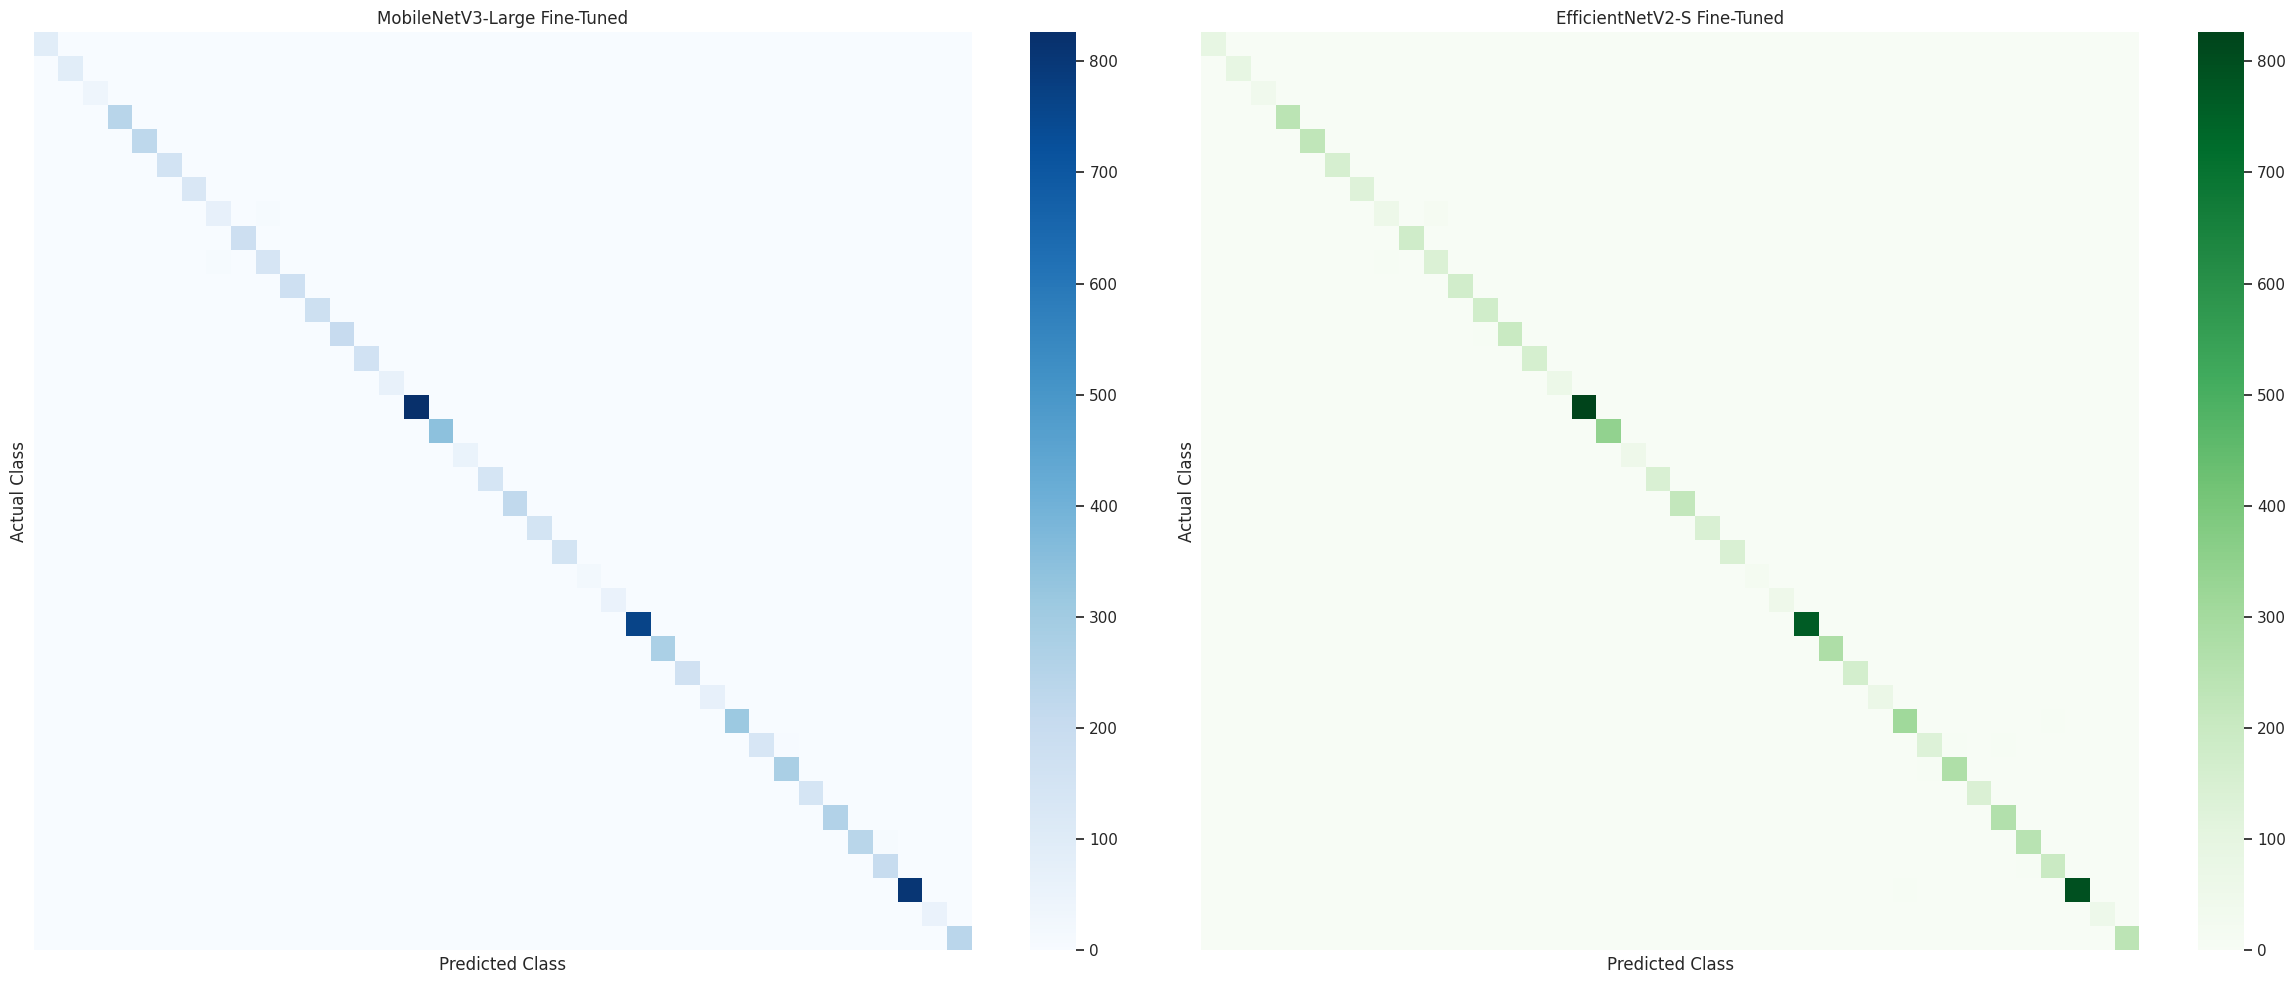

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(24, 10))

sns.heatmap(
    mobilenet_cm,
    cmap="Blues",
    ax=axes[0],
    xticklabels=False,
    yticklabels=False
)

axes[0].set_title("MobileNetV3-Large Fine-Tuned")
axes[0].set_xlabel("Predicted Class")
axes[0].set_ylabel("Actual Class")

sns.heatmap(
    efficientnet_cm,
    cmap="Greens",
    ax=axes[1],
    xticklabels=False,
    yticklabels=False
)

axes[1].set_title("EfficientNetV2-S Fine-Tuned")
axes[1].set_xlabel("Predicted Class")
axes[1].set_ylabel("Actual Class")

plt.tight_layout()
plt.show()

In [ ]:
classes = mobilenet_cm.index.astype(str).tolist()

print("Number of classes:", len(classes))
print("First 5 classes:", classes[:5])

Number of classes: 38
First 5 classes: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy']


In [ ]:
# Remove aggregate rows from classification reports
mobilenet_classes = mobilenet_report.loc[
    mobilenet_report.index.isin(classes)
].copy()

efficientnet_classes = efficientnet_report.loc[
    efficientnet_report.index.isin(classes)
].copy()

# Compare per-class F1 scores
class_comparison = pd.DataFrame({
    "MobileNet F1": mobilenet_classes["f1-score"],
    "EfficientNet F1": efficientnet_classes["f1-score"],
    "MobileNet Recall": mobilenet_classes["recall"],
    "EfficientNet Recall": efficientnet_classes["recall"]
})

class_comparison = class_comparison.sort_values(
    "MobileNet F1"
)

class_comparison.head(10)

,MobileNet F1,EfficientNet F1,MobileNet Recall,EfficientNet Recall
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,0.896104,0.847222,0.896104,0.792208
Tomato___Early_blight,0.934256,0.906574,0.900000,0.873333
Corn_(maize)___Northern_Leaf_Blight,0.942373,0.924590,0.945578,0.959184
Tomato___Target_Spot,0.950820,0.949640,0.962085,0.938389
Potato___healthy,0.956522,0.909091,0.956522,0.869565
Tomato___Spider_mites Two-spotted_spider_mite,0.969819,0.972549,0.956349,0.984127
Apple___Apple_scab,0.973262,0.983957,0.968085,0.978723
Tomato___Late_blight,0.975524,0.961268,0.978947,0.957895
Apple___Cedar_apple_rust,0.975610,1.000000,0.975610,1.000000
Peach___healthy,0.981132,0.972973,0.962963,1.000000


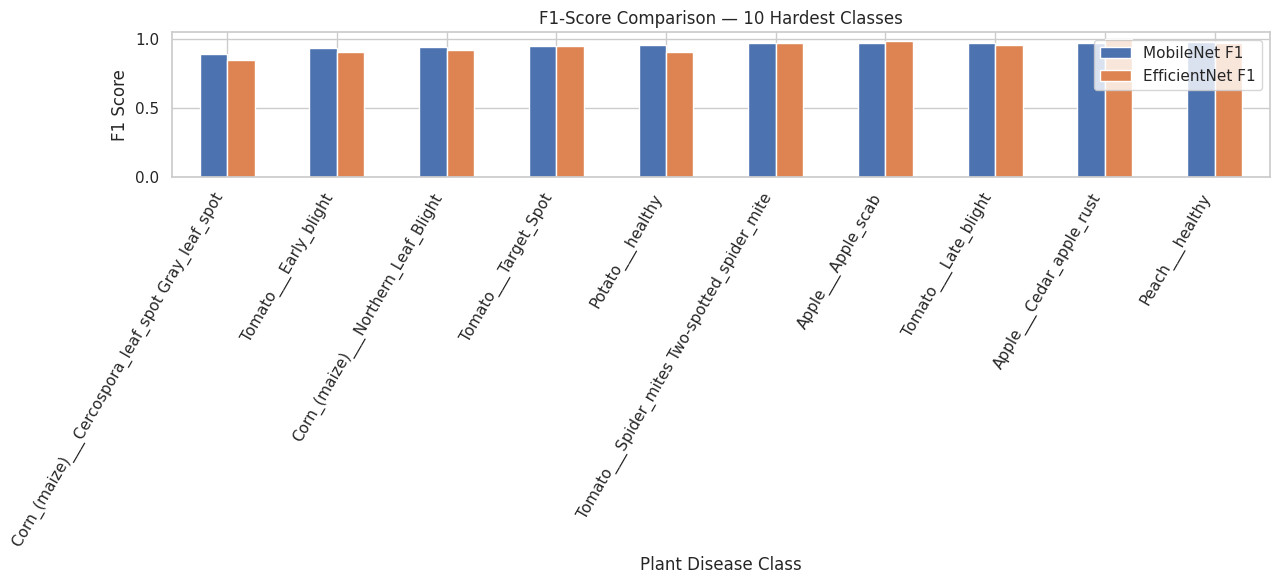

In [ ]:
hardest = class_comparison.head(10).reset_index()

hardest.plot(
    x="index",
    y=["MobileNet F1", "EfficientNet F1"],
    kind="bar",
    figsize=(13, 6)
)

plt.title("F1-Score Comparison — 10 Hardest Classes")
plt.xlabel("Plant Disease Class")
plt.ylabel("F1 Score")
plt.xticks(rotation=60, ha="right")
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

## Per-Class Performance and Error Analysis

Per-class evaluation was conducted using precision, recall and F1-score.

The analysis identified Corn Cercospora leaf spot / Gray leaf spot as one of the most challenging classes for both models. MobileNetV3-Large achieved an F1-score of approximately 89.61%, while EfficientNetV2-S achieved approximately 84.72%.

Other relatively challenging classes included Tomato Early blight and Corn Northern Leaf Blight.

MobileNetV3-Large achieved better F1-scores on most of the ten lowest-performing classes in this comparison. However, EfficientNetV2-S performed better on certain classes, including Apple Cedar apple rust and Tomato Spider mites.

These differences demonstrate that model performance varies across disease categories, even when overall accuracy is high.

Further investigation using misclassified image samples and explainability techniques can help identify possible sources of prediction errors.

In [ ]:
weights = models.MobileNet_V3_Large_Weights.DEFAULT

mobilenet = models.mobilenet_v3_large(weights=None)

num_features = mobilenet.classifier[3].in_features

mobilenet.classifier[3] = nn.Linear(
    num_features, 38
)

mobilenet.load_state_dict(
    torch.load(
        MODEL_DIR / "best_mobilenet_finetuned.pth",
        map_location=device,
        weights_only=True
    )
)

mobilenet = mobilenet.to(device)
mobilenet.eval()

print("Fine-tuned MobileNetV3-Large loaded!")

Fine-tuned MobileNetV3-Large loaded!


In [ ]:
mobilenet_transform = weights.transforms()

print("Input size:", mobilenet_transform.crop_size)

Input size: [224]


In [ ]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.gradients = None
        self.activations = None

        self.forward_handle = target_layer.register_forward_hook(
            self.save_activations
        )

        self.backward_handle = target_layer.register_full_backward_hook(
            self.save_gradients
        )

    def save_activations(self, module, input, output):
        self.activations = output.detach()

    def save_gradients(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, image_tensor, class_index=None):

        self.model.zero_grad(set_to_none=True)

        output = self.model(image_tensor)

        if class_index is None:
            class_index = output.argmax(dim=1).item()

        score = output[:, class_index]
        score.backward()

        weights = self.gradients.mean(
            dim=(2, 3), keepdim=True
        )

        cam = (weights * self.activations).sum(dim=1)

        cam = F.relu(cam)

        cam = F.interpolate(
            cam.unsqueeze(1),
            size=(224, 224),
            mode="bilinear",
            align_corners=False
        )

        cam = cam.squeeze()

        cam -= cam.min()
        cam /= cam.max().clamp(min=1e-8)

        return cam.cpu().numpy(), class_index

    def remove_hooks(self):
        self.forward_handle.remove()
        self.backward_handle.remove()


print("Grad-CAM class implemented successfully!")

Grad-CAM class implemented successfully!


In [ ]:
test_df = pd.read_csv(PROJECT_DIR / "splits" / "test.csv")

print("Test images:", len(test_df))
print(test_df.head())

Test images: 8143
                                          Image_Path  \
0  /content/PlantLeafNet/plantvillage dataset/col...   
1  /content/PlantLeafNet/plantvillage dataset/col...   
2  /content/PlantLeafNet/plantvillage dataset/col...   
3  /content/PlantLeafNet/plantvillage dataset/col...   
4  /content/PlantLeafNet/plantvillage dataset/col...   

                                               Class  
0                               Tomato___Late_blight  
1                               Tomato___Late_blight  
2                             Corn_(maize)___healthy  
3  Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...  
4                                    Apple___healthy  


In [ ]:
print(
    "Existing images:",
    test_df["Image_Path"].apply(lambda p: Path(p).exists()).sum()
)

Existing images: 0


In [ ]:
print("Project folders:")

for item in PROJECT_DIR.iterdir():
    print(item.name)

Project folders:
models
results
splits
class_mapping.json


In [ ]:
for path in Path("/content").rglob("color"):
    if path.is_dir():
        print("Found:", path)

In [ ]:
from pathlib import Path

first_image = Path(test_df.iloc[0]["Image_Path"])

print("Class:", test_df.iloc[0]["Class"])
print("Filename:", first_image.name)
print("Kaggle file path:", first_image.as_posix().split("/color/")[-1])

Class: Tomato___Late_blight
Filename: 9029b453-c7c1-4c80-9033-72b650866290___GHLB2 Leaf 160.1.JPG
Kaggle file path: Tomato___Late_blight/9029b453-c7c1-4c80-9033-72b650866290___GHLB2 Leaf 160.1.JPG


In [ ]:
from google.colab import userdata
import os

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

!pip install -q kaggle

In [ ]:
import os
from pathlib import Path

sample_dir = Path("/content/gradcam_sample")
sample_dir.mkdir(exist_ok=True)

kaggle_file = (
    "color/Tomato___Late_blight/"
    "9029b453-c7c1-4c80-9033-72b650866290___GHLB2 Leaf 160.1.JPG"
)

!kaggle datasets download \
    -d abdallahalidev/plantvillage-dataset \
    -f "{kaggle_file}" \
    -p /content/gradcam_sample

Dataset URL: https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset
License(s): CC-BY-NC-SA-4.0
100% 7.87k/7.87k [00:00<00:00, 26.7MB/s]



In [ ]:
import zipfile

zip_files = list(sample_dir.glob("*.zip"))

for zip_file in zip_files:
    with zipfile.ZipFile(zip_file, "r") as z:
        z.extractall(sample_dir)

image_path = next(sample_dir.rglob("*.JPG"))

print("Image found:", image_path)

Image found: /content/gradcam_sample/9029b453-c7c1-4c80-9033-72b650866290___GHLB2%20Leaf%20160.1.JPG


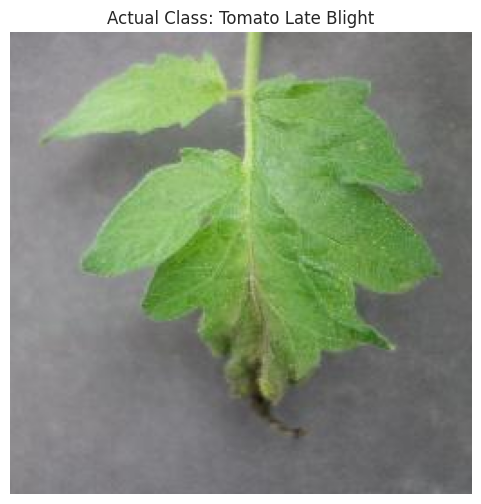

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

original_image = Image.open(image_path).convert("RGB")

plt.figure(figsize=(6, 6))
plt.imshow(original_image)
plt.title("Actual Class: Tomato Late Blight")
plt.axis("off")
plt.show()

In [ ]:
image = Image.open(image_path).convert("RGB")

input_tensor = mobilenet_transform(image).unsqueeze(0).to(device)

print("Input tensor shape:", input_tensor.shape)

Input tensor shape: torch.Size([1, 3, 224, 224])


In [ ]:
gradcam = GradCAM(
    mobilenet,
    mobilenet.features[-1]
)

# Generate heatmap for the predicted class
cam, predicted_class = gradcam.generate(input_tensor)

# Get prediction confidence
with torch.no_grad():
    logits = mobilenet(input_tensor)
    probabilities = torch.softmax(logits, dim=1)

confidence = probabilities[0, predicted_class].item()

predicted_label = classes[predicted_class]
actual_label = "Tomato___Late_blight"

print("Actual class:", actual_label)
print("Predicted class:", predicted_label)
print(f"Confidence: {confidence * 100:.2f}%")
print("Correct prediction:", predicted_label == actual_label)

Actual class: Tomato___Late_blight
Predicted class: Tomato___Late_blight
Confidence: 94.00%
Correct prediction: True


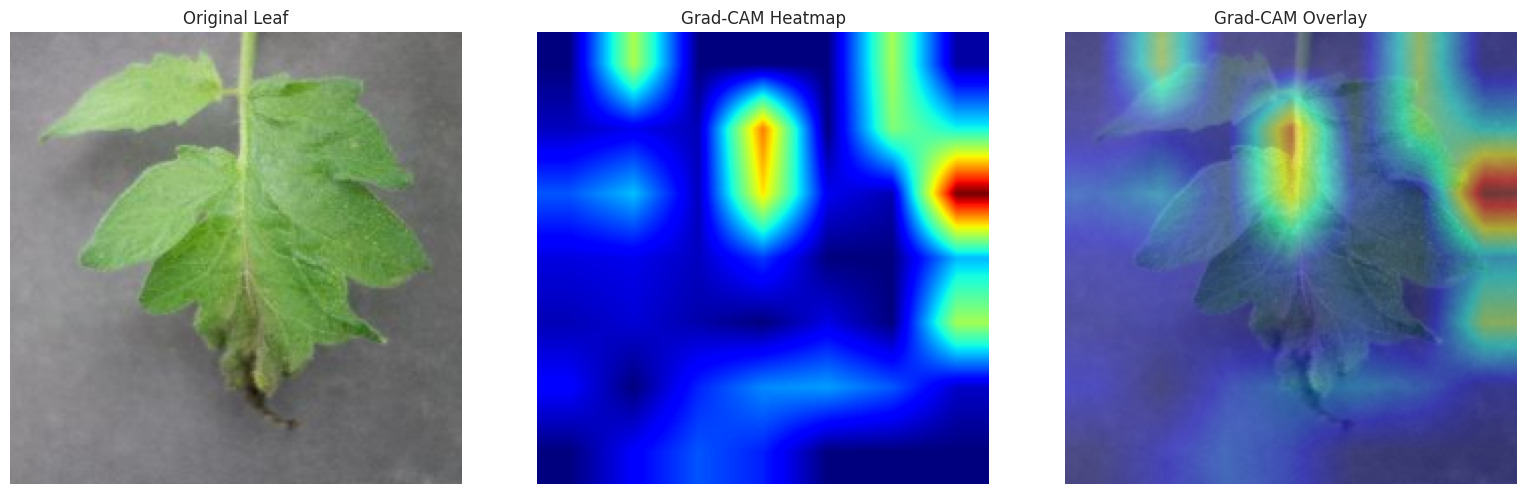

In [ ]:
import cv2

original = np.array(image.resize((224, 224)))

heatmap = cv2.applyColorMap(
    np.uint8(255 * cam),
    cv2.COLORMAP_JET
)

heatmap = cv2.cvtColor(
    heatmap,
    cv2.COLOR_BGR2RGB
)

overlay = cv2.addWeighted(
    original, 0.55,
    heatmap, 0.45,
    0
)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(original)
axes[0].set_title("Original Leaf")

axes[1].imshow(cam, cmap="jet")
axes[1].set_title("Grad-CAM Heatmap")

axes[2].imshow(overlay)
axes[2].set_title("Grad-CAM Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

## Grad-CAM Explainability Analysis

Gradient-weighted Class Activation Mapping (Grad-CAM) was implemented using PyTorch hooks to visualize regions influencing the MobileNetV3-Large model's predictions.

A Tomato Late Blight test image was selected for visualization.

- Actual class: Tomato Late Blight
- Predicted class: Tomato Late Blight
- Prediction confidence: 94.00%
- Prediction result: Correct

The Grad-CAM visualization showed strong activations around parts of the leaf, including its central region. However, some strong activation was also observed near the background outside the leaf.

This observation suggests a potential limitation in the model's attention behaviour. Additional samples should be investigated to determine whether the model relies on background information.

Grad-CAM provides an approximate visual explanation and does not establish causal evidence of which features the model uses.

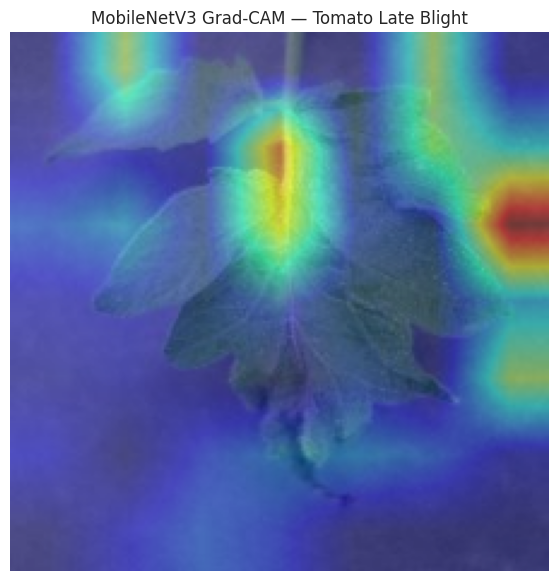

In [ ]:
import cv2

gradcam_dir = RESULT_DIR / "gradcam"
gradcam_dir.mkdir(exist_ok=True)

plt.figure(figsize=(7, 7))
plt.imshow(overlay)
plt.axis("off")
plt.title("MobileNetV3 Grad-CAM — Tomato Late Blight")

plt.savefig(
    gradcam_dir / "tomato_late_blight_gradcam.png",
    bbox_inches="tight",
    dpi=200
)

plt.show()

In [ ]:
evaluation_summary = pd.DataFrame([
    {
        "Model": "MobileNetV3-Large Fine-Tuned",
        "Accuracy": 98.89,
        "Macro Precision": 98.50,
        "Macro Recall": 98.29,
        "Macro F1": 98.39
    },
    {
        "Model": "EfficientNetV2-S Fine-Tuned",
        "Accuracy": 98.46,
        "Macro Precision": 97.92,
        "Macro Recall": 97.70,
        "Macro F1": 97.78
    }
])

evaluation_summary.to_csv(
    RESULT_DIR / "final_evaluation_summary.csv",
    index=False
)

print("Final evaluation summary saved!")

Final evaluation summary saved!


## Evaluation and Explainability — Conclusion

Both fine-tuned pretrained models achieved strong performance on the PlantVillage test dataset.

MobileNetV3-Large achieved 98.89% test accuracy, while EfficientNetV2-S achieved 98.46%.

Confusion matrix analysis showed strong classification performance across the 38 disease classes. Per-class analysis identified certain challenging categories, particularly Corn Cercospora leaf spot and Tomato Early blight.

Grad-CAM was implemented using PyTorch hooks. A Tomato Late Blight test image was correctly classified with 94% confidence. Its visualization revealed activation on both leaf and background regions, highlighting the importance of further explainability and external validation.

The evaluation demonstrates strong performance on the controlled PlantVillage dataset, but independent field-image testing is required before real-world deployment claims can be made.